# AB_vieillissement_couplage — couplage calendaire de la chaîne hydrogène sur toute la vie de la pile

## Système étudié (hypothétique)

Un électrolyseur PEM produit l'hydrogène qui, après compression, alimente la pile PEM d'un véhicule. L'unité fonctionnelle est **1 km parcouru par le véhicule** :

$$I_{km}(t)=\underbrace{m_{H_2/km}\big(t_{FC}(t)\big)}_{\text{pile}}\times\underbrace{I_{kg}\big(t_{WE}(t)\big)}_{\text{électrolyseur + compression}}$$

## Méthode : couplage calendaire intégré sur toute la vie de la pile

Les deux équipements sont reliés par le temps calendaire $t$ (années) :

$$t_{FC}=H_{FC}\,t,\qquad t_{WE}=H_{WE}\,t,\qquad H_{FC}=463\ \text{h/an},\ H_{WE}=6\,000\ \text{h/an}.$$

On suit le système de $t=0$ jusqu'à la fin de vie de la pile ($T_{FC}=3\,119$ h, soit 6,7 ans), puis on calcule l'impact moyen par km sur cette période (le véhicule parcourt le même nombre de km chaque année, donc la moyenne sur les km est la moyenne sur le temps) :

$$\bar I_{km}=\frac{1}{T}\int_0^{T} I_{km}(t)\,dt,\qquad T=T_{FC}/H_{FC}.$$

## Hypothèses

| N° | Hypothèse | Traitement |
|---|---|---|
| H1 | L'électrolyseur et la pile sont mis en service le même jour | sensibilité : électrolyseur démarré 2, 4 ou 6 ans avant |
| H2 | Heures annuelles constantes : pile 463 h/an (16 667 km/an), électrolyseur 6 000 h/an | sensibilité : 4 000 et 8 000 h/an |
| H3 | Tout l'hydrogène produit alimente la pile ; pas de pertes dans le cas central | sensibilité : pertes 0 à 5 % (Monte-Carlo) |
| H4 | L'horizon est la vie de la pile ; si l'électrolyseur atteint sa fin de vie avant, son stack est remplacé par un neuf | dans le cas central, l'électrolyseur n'atteint pas sa fin de vie (40 430 h < 46 533 h) |
| H5 | Inventaires constants (mix électrique, compression 2,8 kWh/kg (Magnaval et al. 2026), eau) | Monte-Carlo : contenu carbone ±20 %, compression 2–5 kWh/kg |
| H6 | Phase d'usage seulement : la fabrication des stacks est traitée dans `AB_vieillissement_fabrication` | voir ce notebook |


> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 1. Données et modèles

Cellules reprises sans modification de `AB_vieillissement_ACV_sensibilite` : profil WLTP, modèle PEMFC (Colombo 2023, Verducci 2027), modèle PEMWE (Padgett 2025, Chandesris 2015) et inventaires EF 3.1.

## 0. Fichiers d'entrée

Cette cellule prépare les fichiers de mesures dont le notebook a besoin, dans le dossier du notebook. Il n'y a rien à faire : exécutez-la simplement.

- Si un fichier est déjà là, il est gardé.
- Sinon, il est pris dans le dossier `data/` du dépôt (si le notebook est dans `h2-ageing-lca/notebooks/`), ou téléchargé depuis le dépôt GitHub public (connexion internet nécessaire).

In [ ]:
BESOINS = ['pemwe_parametres.json']

import json, shutil, urllib.request
from pathlib import Path
import pandas as pd

DEPOT_EN_LIGNE = "https://raw.githubusercontent.com/Ayabh12/h2-ageing-lca/main/"
ICI = Path.cwd()

def source(chemin):
    """Chemin local dans le dépôt si disponible, sinon adresse sur GitHub."""
    for base in (ICI.parent, ICI.parent / "h2-ageing-lca", ICI / "h2-ageing-lca"):
        if (base / chemin).exists():
            return str(base / chemin)
    return DEPOT_EN_LIGNE + chemin

def copier(chemin, nom):
    src = source(chemin)
    if src.startswith(("http://", "https://", "file:")):
        urllib.request.urlretrieve(src, ICI / nom)
    else:
        shutil.copy(src, ICI / nom)

def preparer(nom, fabrication):
    if (ICI / nom).exists():
        print(f"déjà présent : {nom}")
    else:
        fabrication()
        print(f"préparé      : {nom}")

def _signaux():
    sig = pd.read_csv(source("data/measurements/mirai2_fuel_cell_signals.csv"))
    sig.columns = ["Temps (s)", "Vitesse (km/h)", "Courant FC (A)", "Tension FC (V)", "Niveau hydrogène restant (%)"]
    sig.to_excel(ICI / "signaux_fuel_cell_1.xlsx", index=False)

def _trajet():
    trip = pd.read_csv(source("data/measurements/mirai2_fuel_cell_trip.csv"))
    trip.columns = ["Temps (s)", "Courant FC (A)", "Tension FC (V)"]
    trip.to_excel(ICI / "mirai2_fuel_cell_trip.xlsx", sheet_name="wltp", index=False)

FICHIERS = {
    "signaux_fuel_cell_1.xlsx": _signaux,
    "mirai2_fuel_cell_trip.xlsx": _trajet,
    "profil_electrolyseur_ACV_duree_vie (2).xlsx": lambda: copier("data/measurements/nel_mc250_wind_profile.xlsx", "profil_electrolyseur_ACV_duree_vie (2).xlsx"),
    "pemwe_parametres.json": lambda: copier("data/parameters/pemwe_fit.json", "pemwe_parametres.json"),
    "medium.xlsx": lambda: copier("notebooks/medium.xlsx", "medium.xlsx"),
    "nuc.xlsx": lambda: copier("notebooks/nuc.xlsx", "nuc.xlsx"),
    "wind.xlsx": lambda: copier("notebooks/wind.xlsx", "wind.xlsx"),
    "pv.xlsx": lambda: copier("notebooks/pv.xlsx", "pv.xlsx"),
}
for nom in BESOINS:
    preparer(nom, FICHIERS[nom])

In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


In [2]:
OUT=Path("resultats_couplage");OUT.mkdir(exist_ok=True)

In [3]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


In [4]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


In [5]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


## 2. Trajectoires calendaires (cas central)

À chaque instant $t$ : âge de la pile $463\,t$, âge de l'électrolyseur $6\,000\,t$ (remplacé à sa fin de vie si nécessaire, H4). On calcule l'hydrogène consommé par km, l'impact d'un kg et l'impact par km.

In [6]:
HWE_AN=6000.
def trajectoire(pf=FC_CENTRAL,pw=WE_CENTRAL,hwe=HWE_AN,decal=0.,n=61,loss=0,comp=E_COMP,cf=1):
 Tf=fc_eol(pf);Tw=we_eol(pw);yrs=np.linspace(0,Tf/HFC_AN,n)
 afc=yrs*HFC_AN;awe=np.mod((yrs+decal)*hwe,Tw)
 m=np.array([fc_state(a,pf)["H2"] for a in afc])/DIST
 sec=np.array([float(we_state(a,pw)["SEC"]) for a in awe])
 ikg=np.array([impactkg(s,loss,comp,cf).reindex(IND).to_numpy() for s in sec])
 return {"ans":yrs,"age_FC":afc,"age_WE":awe,"m":m,"SEC":sec,"Ikg":ikg,"Ikm":m[:,None]*ikg,"T_FC":Tf,"T_WE":Tw,"rempl":int(((yrs[-1]+decal)*hwe)//Tw)}
def moyenne_vie(tr):
 return pd.Series(trapz(tr["Ikm"],tr["ans"],axis=0)/tr["ans"][-1],index=IND)
G=IND.index(GWP)
M0=FC_H2EXP0/DIST;I0=impactkg(WE_SEC0).reindex(IND);IKM0=M0*I0
TR=trajectoire()
IKM_CAL=moyenne_vie(TR)
print(f"Horizon : {TR['ans'][-1]:.2f} ans ; pile {TR['age_FC'][-1]:.0f} h (fin de vie) ; électrolyseur {TR['age_WE'][-1]:.0f} h (fin de vie {TR['T_WE']:.0f} h) ; remplacements électrolyseur : {TR['rempl']}")
print(f"Impact par km : neuf {1000*IKM0[GWP]:.3f} g ; fin de vie de la pile {1000*TR['Ikm'][-1,G]:.3f} g ; moyenne sur la vie {1000*IKM_CAL[GWP]:.3f} g CO2-éq/km (+{100*(IKM_CAL[GWP]/IKM0[GWP]-1):.2f} %)")
traj=pd.DataFrame({"Années":TR["ans"],"Âge pile (h)":TR["age_FC"],"Âge électrolyseur (h)":TR["age_WE"],"H2 (g/km)":1000*TR["m"],"SEC (kWh/kg)":TR["SEC"],
 "Impact/kg (kg CO2-éq)":TR["Ikg"][:,G],"Impact/km (g CO2-éq)":1000*TR["Ikm"][:,G]})
display(traj.iloc[::10].round(3))


Horizon : 10.34 ans ; pile 3828 h (fin de vie) ; électrolyseur 15491 h (fin de vie 46533 h) ; remplacements électrolyseur : 1
Impact par km : neuf 43.422 g ; fin de vie de la pile 50.808 g ; moyenne sur la vie 48.812 g CO2-éq/km (+12.41 %)


,Années,Âge pile (h),Âge électrolyseur (h),H2 (g/km),SEC (kWh/kg),Impact/kg (kg CO2-éq),Impact/km (g CO2-éq)
0,0.000,0.000,0.000,9.644,53.676,4.503,43.422
10,1.723,637.983,10337.359,9.898,55.684,4.662,46.151
20,3.446,1275.966,20674.717,10.089,57.039,4.770,48.127
30,5.169,1913.948,31012.076,10.265,58.410,4.880,50.087
40,6.892,2551.931,41349.434,10.435,59.800,4.990,52.074
50,8.614,3189.914,5153.517,10.604,55.000,4.608,48.862
60,10.337,3827.897,15490.876,10.773,56.358,4.716,50.808


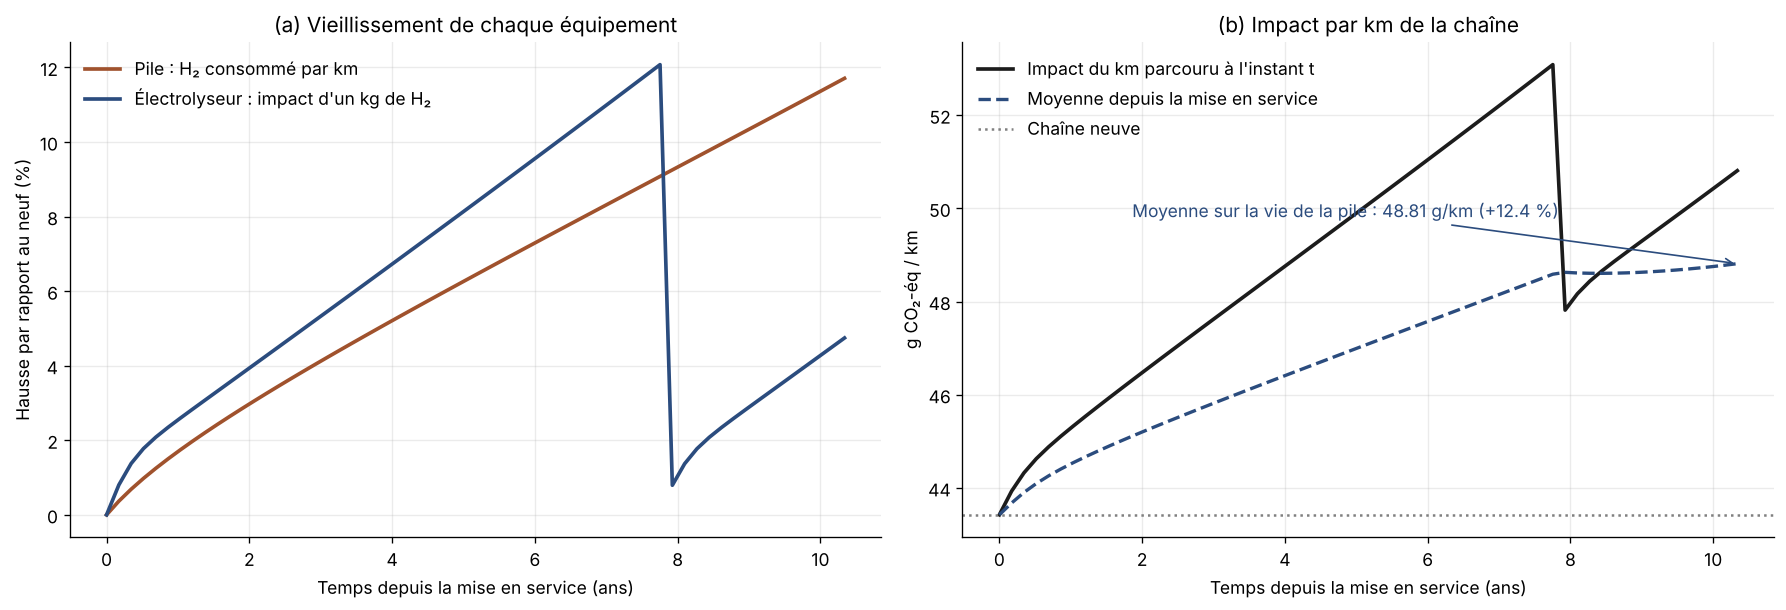

In [7]:
ans=TR["ans"];moy_glissante=np.r_[TR["Ikm"][0,G],np.cumsum(.5*(TR["Ikm"][1:,G]+TR["Ikm"][:-1,G])*np.diff(ans))/ans[1:]]
fig,axs=plt.subplots(1,2,figsize=(15,5.2))
axs[0].plot(ans,100*(TR["m"]/M0-1),color="#A0522D",lw=2.2,label="Pile : H₂ consommé par km")
axs[0].plot(ans,100*(TR["Ikg"][:,G]/I0[GWP]-1),color="#2B4C7E",lw=2.2,label="Électrolyseur : impact d'un kg de H₂")
axs[0].set(xlabel="Temps depuis la mise en service (ans)",ylabel="Hausse par rapport au neuf (%)",title="(a) Vieillissement de chaque équipement");axs[0].legend(frameon=False)
axs[1].plot(ans,1000*TR["Ikm"][:,G],color="#1C1C1C",lw=2.2,label="Impact du km parcouru à l'instant t")
axs[1].plot(ans,1000*moy_glissante,color="#2B4C7E",lw=2,ls="--",label="Moyenne depuis la mise en service")
axs[1].axhline(1000*IKM0[GWP],color="grey",ls=":",label="Chaîne neuve")
axs[1].annotate(f"Moyenne sur la vie de la pile : {1000*IKM_CAL[GWP]:.2f} g/km (+{100*(IKM_CAL[GWP]/IKM0[GWP]-1):.1f} %)",xy=(ans[-1],1000*IKM_CAL[GWP]),xytext=(ans[-1]*0.18,1000*IKM_CAL[GWP]+1.0),arrowprops=dict(arrowstyle="->",color="#2B4C7E"),color="#2B4C7E")
axs[1].set(xlabel="Temps depuis la mise en service (ans)",ylabel="g CO₂-éq / km",title="(b) Impact par km de la chaîne");axs[1].legend(frameon=False,loc="upper left")
fig.tight_layout();fig.savefig(OUT/"CAL_01_trajectoires.png",dpi=220);plt.show()


## 3. Impact cumulé sur la vie de la pile

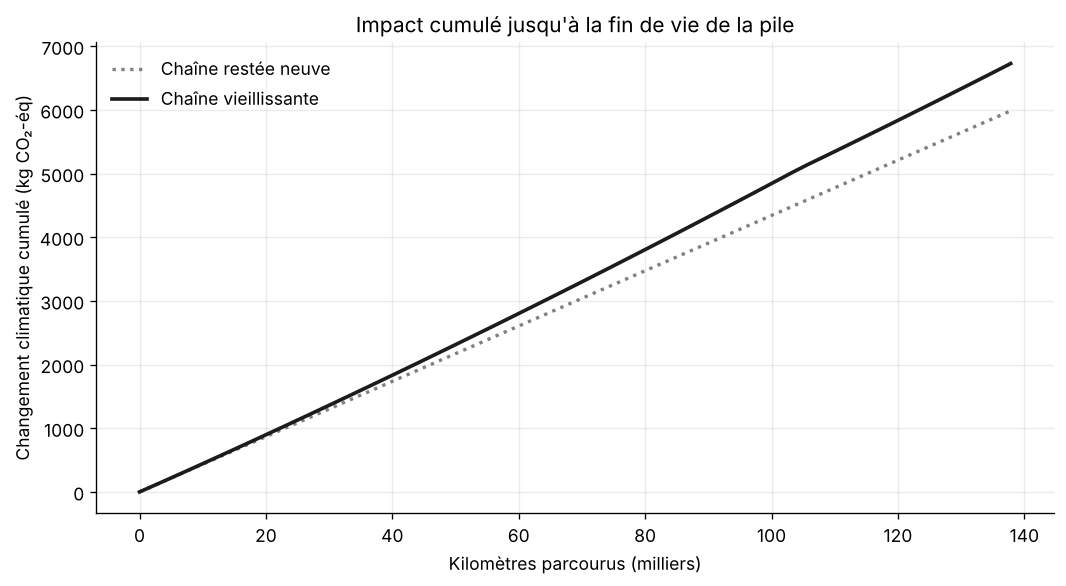

Sur 137 831 km : 6 728 kg CO2-éq contre 5 985 si la chaîne restait neuve (+12.4 %)


,Neuf (par km),"Vieillie, moyenne sur la vie (par km)",Hausse_pct
Acidification,1.428522e-04,1.605687e-04,12.402039
Changement climatique,4.342228e-02,4.881245e-02,12.413363
Écotoxicité totale,9.325861e-02,1.045368e-01,12.093432
Écotoxicité inorganique,9.125377e-02,1.022834e-01,12.086753
Écotoxicité organique,2.004837e-03,2.253385e-03,12.397406
Énergie fossile,7.621944e+00,8.568540e+00,12.419351
Eutrophisation eau douce,6.108325e-06,6.865761e-06,12.400064
Eutrophisation marine,5.438808e-05,6.114016e-05,12.414639
Eutrophisation terrestre,3.660645e-04,4.114998e-04,12.411826
Toxicité humaine totale,1.280310e-11,1.438750e-11,12.375136


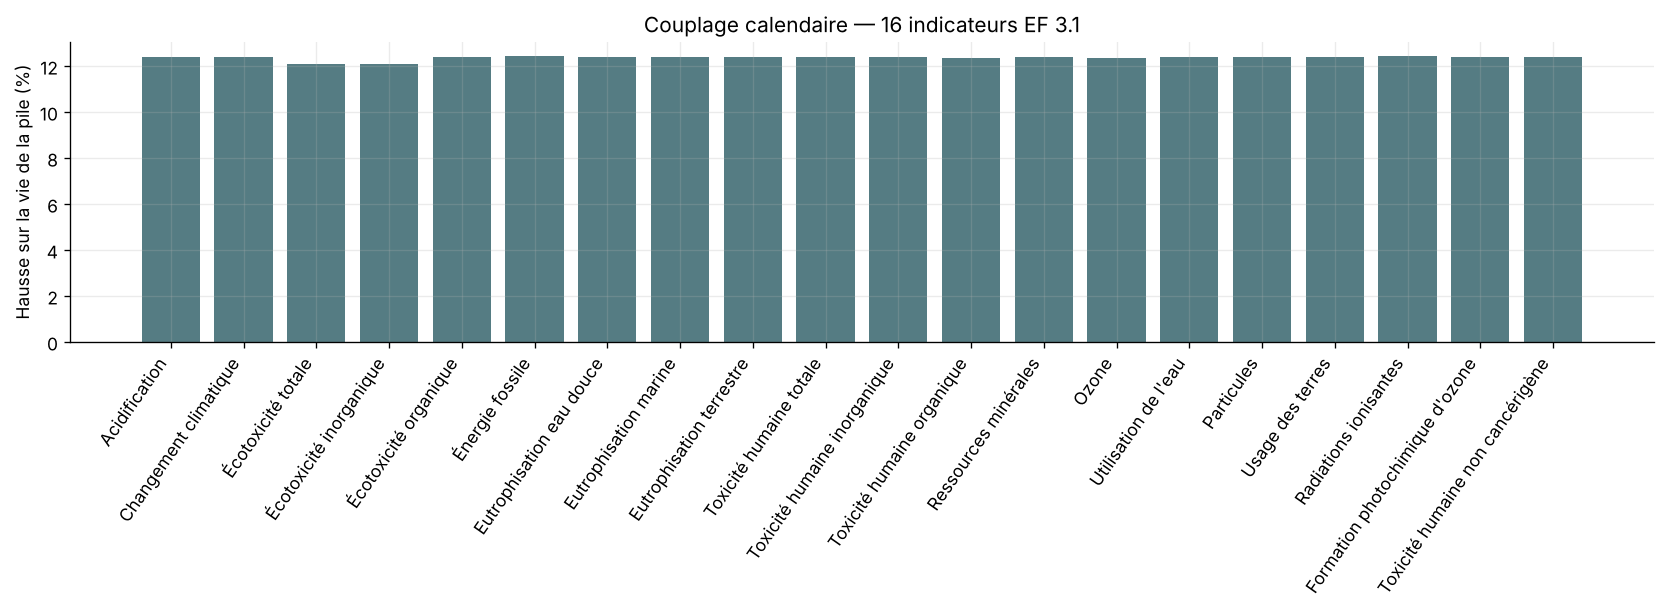

In [8]:
km_an=200000./15.;km=ans*km_an
cum=np.r_[0,np.cumsum(.5*(TR["Ikm"][1:,G]+TR["Ikm"][:-1,G])*np.diff(km))]
cum0=IKM0[GWP]*km
fig,ax=plt.subplots(figsize=(9,5));ax.plot(km/1000,cum0,color="grey",ls=":",lw=2,label="Chaîne restée neuve");ax.plot(km/1000,cum,color="#1C1C1C",lw=2.2,label="Chaîne vieillissante")
ax.set(xlabel="Kilomètres parcourus (milliers)",ylabel="Changement climatique cumulé (kg CO₂-éq)",title="Impact cumulé jusqu'à la fin de vie de la pile");ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"CAL_02_cumul.png",dpi=220);plt.show()
print(f"Sur {km[-1]:,.0f} km : {cum[-1]:,.0f} kg CO2-éq contre {cum0[-1]:,.0f} si la chaîne restait neuve (+{100*(cum[-1]/cum0[-1]-1):.1f} %)".replace(","," "))
tab16=pd.DataFrame({"Neuf (par km)":IKM0,"Vieillie, moyenne sur la vie (par km)":IKM_CAL,"Hausse_pct":100*(IKM_CAL/IKM0-1)}).loc[IND]
display(tab16)
fig,ax=plt.subplots(figsize=(14,5.2));ax.bar(np.arange(len(IND)),tab16.Hausse_pct,color="#557C83")
ax.set_xticks(np.arange(len(IND)),IND,rotation=55,ha="right");ax.set(ylabel="Hausse sur la vie de la pile (%)",title="Couplage calendaire — 16 indicateurs EF 3.1")
fig.tight_layout();fig.savefig(OUT/"CAL_05_16_indicateurs.png",dpi=220);plt.show()


## 4. Sensibilité aux hypothèses du couplage

- **H1** : l'électrolyseur est mis en service 0, 2, 4 ou 6 ans avant la pile (stack remplacé à sa fin de vie).
- **H2** : l'électrolyseur fonctionne 4 000, 6 000 ou 8 000 h/an.

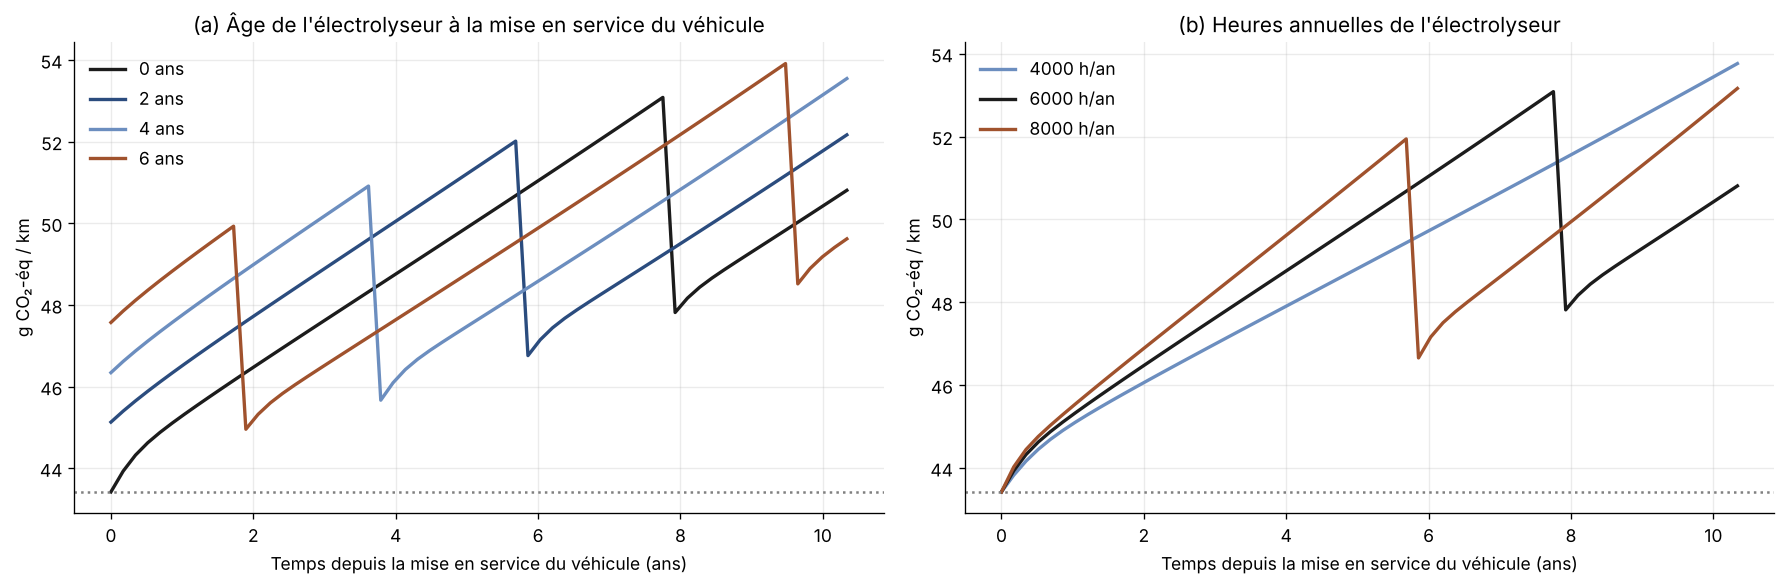

,Hypothèse,Valeur,g CO2-éq/km,Hausse_pct,Remplacements électrolyseur
0,H1 : électrolyseur démarré avant la pile,0 ans,48.812,12.413,1
1,H1 : électrolyseur démarré avant la pile,2 ans,49.092,13.057,1
2,H1 : électrolyseur démarré avant la pile,4 ans,49.383,13.728,1
3,H1 : électrolyseur démarré avant la pile,6 ans,49.385,13.732,2
4,H2 : heures annuelles de l'électrolyseur,4000 h/an,48.937,12.701,0
5,H2 : heures annuelles de l'électrolyseur,6000 h/an,48.812,12.413,1
6,H2 : heures annuelles de l'électrolyseur,8000 h/an,48.923,12.669,1


In [9]:
rows=[];fig,axs=plt.subplots(1,2,figsize=(15,5))
for d,c in zip([0,2,4,6],["#1C1C1C","#2B4C7E","#6C8EBF","#A0522D"]):
 tr=trajectoire(decal=d);v=moyenne_vie(tr)[GWP]
 rows.append({"Hypothèse":"H1 : électrolyseur démarré avant la pile","Valeur":f"{d} ans","g CO2-éq/km":1000*v,"Hausse_pct":100*(v/IKM0[GWP]-1),"Remplacements électrolyseur":tr["rempl"]})
 axs[0].plot(tr["ans"],1000*tr["Ikm"][:,G],color=c,lw=2,label=f"{d} ans")
for h,c in zip([4000,6000,8000],["#6C8EBF","#1C1C1C","#A0522D"]):
 tr=trajectoire(hwe=h);v=moyenne_vie(tr)[GWP]
 rows.append({"Hypothèse":"H2 : heures annuelles de l'électrolyseur","Valeur":f"{h} h/an","g CO2-éq/km":1000*v,"Hausse_pct":100*(v/IKM0[GWP]-1),"Remplacements électrolyseur":tr["rempl"]})
 axs[1].plot(tr["ans"],1000*tr["Ikm"][:,G],color=c,lw=2,label=f"{h} h/an")
for ax,t in zip(axs,["(a) Âge de l'électrolyseur à la mise en service du véhicule","(b) Heures annuelles de l'électrolyseur"]):
 ax.axhline(1000*IKM0[GWP],color="grey",ls=":");ax.set(xlabel="Temps depuis la mise en service du véhicule (ans)",ylabel="g CO₂-éq / km",title=t);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"CAL_03_sensibilite_hypotheses.png",dpi=220);plt.show()
sens_hyp=pd.DataFrame(rows);display(sens_hyp.round(3))


## 5. Scénarios de vieillissement et Monte-Carlo

In [10]:
mat=pd.DataFrame({w:{f:100*(moyenne_vie(trajectoire(pf,pw,n=41))[GWP]/IKM0[GWP]-1) for f,pf in FC_SCEN.items()} for w,pw in WE_SCEN.items()})
mat.index.name="Pile \\ Électrolyseur";print("Hausse de l'impact par km sur la vie de la pile (%)");display(mat.round(2))


Hausse de l'impact par km sur la vie de la pile (%)


,Optimiste,Moyen,Pessimiste
Pile \ Électrolyseur,,,
Optimiste,11.68,12.48,12.66
Moyen,13.18,12.47,13.25
Pessimiste,12.58,14.06,13.52


,Analyse,Sortie,P5,Médiane,P95
0,Couplage calendaire,Impact_g_km,43.779,50.464,57.009
1,Couplage calendaire,Hausse_vieillissement_pct,10.641,12.608,15.995
2,Couplage calendaire,T_FC_h,2927.480,3770.336,5524.962
3,Couplage calendaire,Horizon_ans,7.906,10.182,14.920


,Entrée,Rho impact,Rho hausse
0,fc_omega,-0.000,0.007
7,Heures_WE_an,-0.004,-0.027
5,we_fA_min,-0.008,-0.106
4,we_k_R,0.009,-0.026
1,fc_S1000,0.014,0.010
6,we_t50,0.016,0.002
9,Compression,0.119,-0.035
8,Pertes_H2,0.120,0.059
2,fc_k_R,-0.145,-0.496
3,fc_k_mem,0.146,0.811


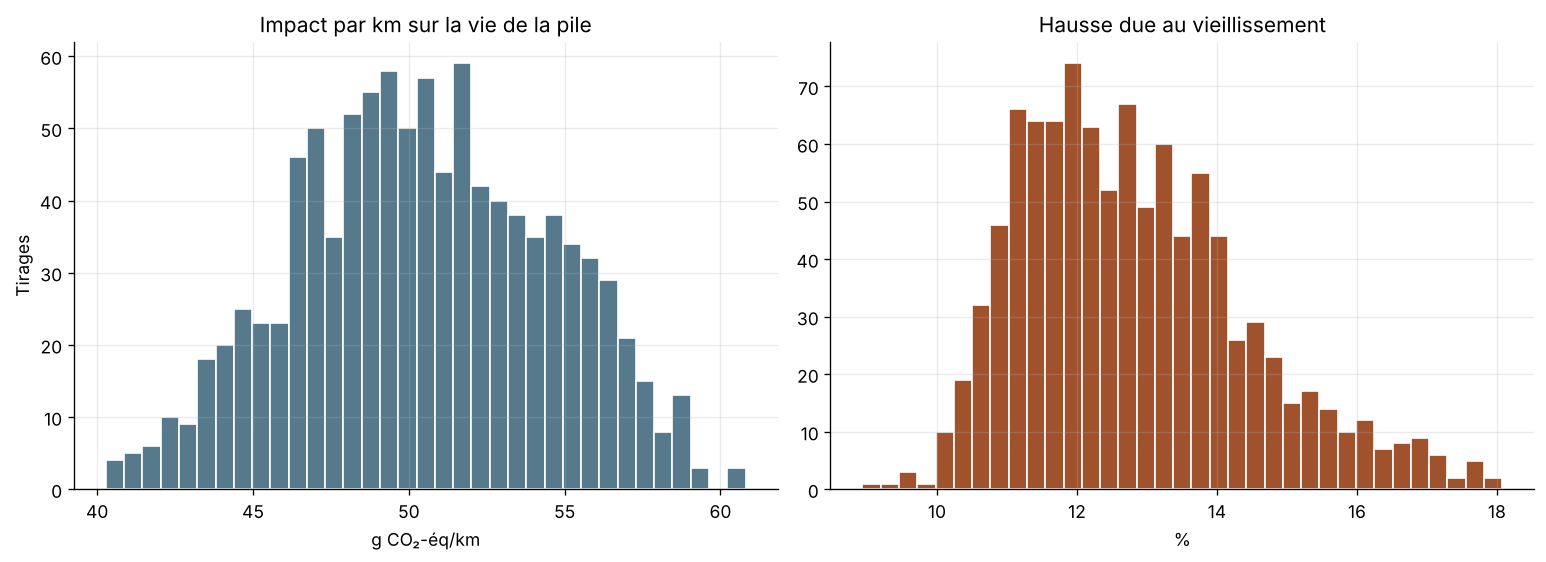

In [11]:
rng=np.random.default_rng(46);NMC=N_MC
cin=pd.DataFrame({"fc_omega":rng.uniform(*FC_BOUNDS["omega"],NMC),"fc_S1000":rng.uniform(*FC_BOUNDS["S1000"],NMC),
"fc_k_R":rng.uniform(*FC_BOUNDS["k_R"],NMC),"fc_k_mem":rng.uniform(*FC_BOUNDS["k_mem"],NMC),
"we_k_R":rng.uniform(PADGETT["dHFR"],PADGETT["dHFR"]+PADGETT["dCLR"],NMC)/WE_R0,
"we_fA_min":rng.uniform(PADGETT["fA_masse"],PADGETT["fA_capa"],NMC),
"we_t50":rng.uniform(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"],NMC),
"Heures_WE_an":rng.triangular(4000,6000,8000,NMC),
"Pertes_H2":rng.triangular(0,.01,.05,NMC),"Compression":rng.triangular(2,3,5,NMC),"CF_electricite":rng.triangular(.8,1,1.2,NMC)})
out=[]
for _,r0 in cin.iterrows():
 pf=FC_CENTRAL.copy();pw=WE_CENTRAL.copy()
 pf.update({"omega":r0.fc_omega,"S1000":r0.fc_S1000,"k_R":r0.fc_k_R,"k_mem":r0.fc_k_mem});pw.update({"k_R":r0.we_k_R,"fA_min":r0.we_fA_min,"t50_mem":r0.we_t50})
 tr=trajectoire(pf,pw,hwe=r0.Heures_WE_an,n=21,loss=r0.Pertes_H2,comp=r0.Compression,cf=r0.CF_electricite)
 v=moyenne_vie(tr)[GWP];ref=M0*impactkg(WE_SEC0,r0.Pertes_H2,r0.Compression,r0.CF_electricite)[GWP]
 out.append({"Impact_g_km":1000*v,"Hausse_vieillissement_pct":100*(v/ref-1),"T_FC_h":tr["T_FC"],"Horizon_ans":tr["ans"][-1]})
mc=pd.concat([cin,pd.DataFrame(out)],axis=1)
mc_sum=percentiles(mc,["Impact_g_km","Hausse_vieillissement_pct","T_FC_h","Horizon_ans"],"Couplage calendaire");display(mc_sum.round(3))
rho=pd.DataFrame([{"Entrée":x,"Rho impact":spearmanr(mc[x],mc.Impact_g_km).statistic,"Rho hausse":spearmanr(mc[x],mc.Hausse_vieillissement_pct).statistic} for x in cin]).sort_values("Rho impact",key=abs)
display(rho.round(3))
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
axs[0].hist(mc.Impact_g_km,bins=35,color="#567A8C",edgecolor="white");axs[0].set(xlabel="g CO₂-éq/km",ylabel="Tirages",title="Impact par km sur la vie de la pile")
axs[1].hist(mc.Hausse_vieillissement_pct,bins=35,color="#A0522D",edgecolor="white");axs[1].set(xlabel="%",title="Hausse due au vieillissement")
fig.tight_layout();fig.savefig(OUT/"CAL_04_MonteCarlo.png",dpi=220);plt.show()


## 6. Comparaison avec les autres lectures

- **Bornes** : chaîne neuve ; pile et électrolyseur tous deux en fin de vie.
- **Lecture à une date** : impact du km parcouru à 2 000 h de pile (instant fixé).
- **Moyenne sur la durée de vie de chaque équipement, âges indépendants** : vérification ; elle correspond à la moyenne du couplage calendaire sur toutes les dates de démarrage (H1).

In [12]:
def ikm_etat(tfc,twe):return fc_state(tfc,FC_CENTRAL)["H2"]/DIST*impactkg(float(we_state(twe,WE_CENTRAL)["SEC"])).reindex(IND)
Tf=TR["T_FC"];Tw=TR["T_WE"]
a=np.linspace(0,Tf,41);mbar=trapz(np.array([fc_state(x,FC_CENTRAL)["H2"] for x in a]),a)/Tf/DIST
b=np.linspace(0,Tw,401);q=we_state(b,WE_CENTRAL);ikg=np.array([impactkg(s).reindex(IND).to_numpy() for s in np.asarray(q["SEC"])])
ibar=pd.Series(trapz(np.asarray(q["H2"])[:,None]*ikg,b,axis=0)/trapz(np.asarray(q["H2"]),b),index=IND)
comp=pd.DataFrame({k:{"g CO2-éq/km":1000*v[GWP],"Hausse_pct":100*(v[GWP]/IKM0[GWP]-1)} for k,v in {
 "Chaîne neuve (borne basse)":IKM0,
 "Lecture à 2 000 h de pile (instant fixé)":ikm_etat(2000,2000/HFC_AN*HWE_AN),
 "Calendaire sur toute la vie de la pile (retenu)":IKM_CAL,
 "Moyenne sur la vie, âges indépendants (vérification)":mbar*ibar,
 "Pile et électrolyseur en fin de vie (borne haute)":ikm_etat(Tf,Tw)}.items()}).T
display(comp.round(3))
checks={"Neuf : 0,196 kg/WLTP":np.isclose(fc_state(0,FC_CENTRAL)["H2"],.196),
"Retenu entre les bornes":bool(comp.iloc[0,0]<comp.iloc[2,0]<comp.iloc[4,0]),
"Remplacements de l'électrolyseur comptés (1 depuis la surface de 297 cm², la pile durant plus longtemps)":TR["rempl"] in (0,1),
"Monte-Carlo fini":bool(np.isfinite(mc.Impact_g_km).all())}
display(pd.DataFrame({"Contrôle":checks.keys(),"OK":checks.values()}));assert all(checks.values())
traj.to_csv(OUT/"CAL_trajectoire_centrale.csv",index=False,encoding="utf-8-sig");tab16.to_csv(OUT/"CAL_16_indicateurs.csv",encoding="utf-8-sig")
sens_hyp.to_csv(OUT/"CAL_sensibilite_hypotheses.csv",index=False,encoding="utf-8-sig");mat.to_csv(OUT/"CAL_matrice_scenarios.csv",encoding="utf-8-sig")
mc.to_csv(OUT/"CAL_MonteCarlo.csv",index=False,encoding="utf-8-sig");comp.to_csv(OUT/"CAL_comparaison.csv",encoding="utf-8-sig")
print("Couplage calendaire validé. Résultats :",OUT.resolve())


,g CO2-éq/km,Hausse_pct
Chaîne neuve (borne basse),43.422,0.000
Lecture à 2 000 h de pile (instant fixé),50.353,15.961
Calendaire sur toute la vie de la pile (retenu),48.812,12.413
"Moyenne sur la vie, âges indépendants (vérification)",49.179,13.257
Pile et électrolyseur en fin de vie (borne haute),54.366,25.203


,Contrôle,OK
0,"Neuf : 0,196 kg/WLTP",True
1,Retenu entre les bornes,True
2,"Remplacements de l'électrolyseur comptés (1 depuis la surface de 297 cm², la pile durant plus longtemps)",True
3,Monte-Carlo fini,True


Couplage calendaire validé. Résultats : ./resultats_couplage


## 7. Limites

| Limite | Effet | Traitement |
|---|---|---|
| Démarrage le même jour (H1) | fixe l'âge de l'électrolyseur vu par la pile | testé : 0 à 6 ans d'avance |
| Heures annuelles supposées (H2) | fixent le rapport des âges | testé : 4 000 à 8 000 h/an |
| Un seul véhicule et un seul électrolyseur | ne représente pas une station réelle | perspective : couplage par les flux sur un cas réel |
| Fabrication des stacks non comptée ici (H6) | sous-estime l'impact des remplacements | traitée dans `AB_vieillissement_fabrication` |
| Inventaires constants (H5) | le mix électrique peut évoluer en 6,7 ans | Monte-Carlo sur le contenu carbone ; perspective ACV dynamique |
| Vieillissement indexé sur les heures de fonctionnement | arrêts et vieillissement à l'arrêt de la pile non comptés | sous-estimation probable côté pile |
